<a href="https://colab.research.google.com/github/UnnimayaVAshok/Data_Science/blob/main/Class_works/sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import SnowballStemmer

In [45]:
data = pd.read_csv('/content/twitter_validation.csv',header = None,encoding = 'ISO-8859-1')
df = pd.DataFrame(data)
df

,0,1,2,3
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...
...,...,...,...,...
995,4891,GrandTheftAuto(GTA),Irrelevant,â­ï¸ Toronto is the arts and culture capital...
996,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
997,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [46]:
df.columns = ['id','media','target','text']
df

,id,media,target,text
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...
...,...,...,...,...
995,4891,GrandTheftAuto(GTA),Irrelevant,â­ï¸ Toronto is the arts and culture capital...
996,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
997,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [47]:
df.columns

Index(['id', 'media', 'target', 'text'], dtype='object')

In [48]:
df.dtypes

,0
id,int64
media,object
target,object
text,object


In [49]:
df.shape

(1000, 4)

In [50]:
df.head()

,id,media,target,text
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...


In [51]:
df.tail()

,id,media,target,text
995,4891,GrandTheftAuto(GTA),Irrelevant,â­ï¸ Toronto is the arts and culture capital...
996,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
997,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.
999,6960,johnson&johnson,Neutral,Johnson & Johnson to stop selling talc baby po...


In [52]:
df.describe(include='all')

,id,media,target,text
count,1000.000000,1000,1000,1000
unique,NaN,32,4,999
top,NaN,RedDeadRedemption(RDR),Neutral,Wow
freq,NaN,40,285,2
mean,6432.088000,NaN,NaN,NaN
std,3728.310569,NaN,NaN,NaN
min,6.000000,NaN,NaN,NaN
25%,3247.750000,NaN,NaN,NaN
50%,6550.000000,NaN,NaN,NaN
75%,9661.750000,NaN,NaN,NaN


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      1000 non-null   int64 
 1   media   1000 non-null   object
 2   target  1000 non-null   object
 3   text    1000 non-null   object
dtypes: int64(1), object(3)
memory usage: 31.4+ KB


In [54]:
df.isna().sum()

,0
id,0
media,0
target,0
text,0


In [55]:
df.duplicated().sum()

np.int64(0)

In [56]:
df_1 = df['media'].value_counts()
df_1

,count
media,
RedDeadRedemption(RDR),40
johnson&johnson,39
PlayerUnknownsBattlegrounds(PUBG),38
FIFA,38
LeagueOfLegends,37
ApexLegends,36
Nvidia,35
TomClancysRainbowSix,35
GrandTheftAuto(GTA),35


In [57]:
df['media'].nunique()

32

Text(0, 0.5, 'Count')

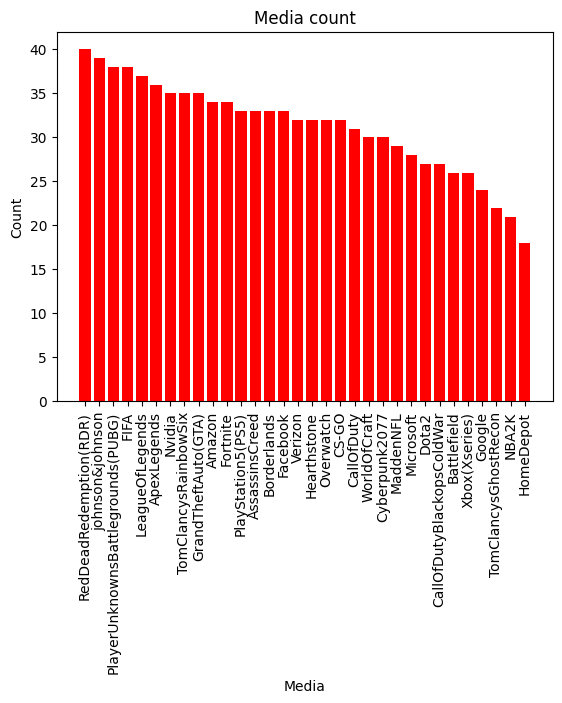

In [58]:
plt.bar(df_1.index,df_1.values,color='r')
plt.title("Media count")
plt.xlabel("Media")
plt.xticks(rotation=90)
plt.ylabel("Count")

In [59]:
df_2 = df['target'].value_counts()
df_2

,count
target,
Neutral,285
Positive,277
Negative,266
Irrelevant,172


Text(0.5, 1.0, 'Target comparison')

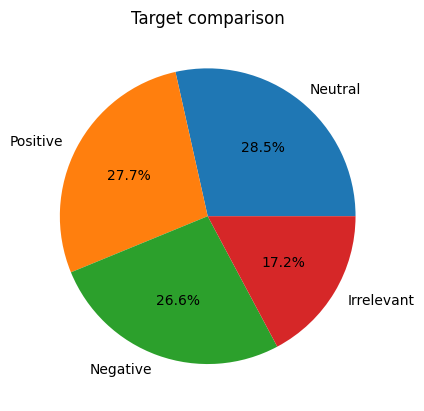

In [60]:
plt.pie(df_2.values,labels=df_2.index,autopct='%1.1f%%')
plt.title("Target comparison")

In [61]:
df.drop(df.index[df['target']=='Irrelevant'],axis=0,inplace=True)
df

,id,media,target,text
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...
5,6273,FIFA,Negative,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...,...,...
993,314,Amazon,Negative,Please explain how this is possible! How can t...
994,9701,PlayStation5(PS5),Positive,Good on Sony. As much as I want to see the new...
997,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [62]:
df.reset_index(drop=True,inplace=True)
df

,id,media,target,text
0,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
2,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,4433,Google,Neutral,Now the President is slapping Americans in the...
4,6273,FIFA,Negative,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...,...,...
823,314,Amazon,Negative,Please explain how this is possible! How can t...
824,9701,PlayStation5(PS5),Positive,Good on Sony. As much as I want to see the new...
825,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
826,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [63]:
df.drop(['id','media'],axis=1,inplace=True)
df

,target,text
0,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,Negative,@Microsoft Why do I pay for WORD when it funct...
2,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,Neutral,Now the President is slapping Americans in the...
4,Negative,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...
823,Negative,Please explain how this is possible! How can t...
824,Positive,Good on Sony. As much as I want to see the new...
825,Positive,Today sucked so itâs time to drink wine n pl...
826,Positive,Bought a fraction of Microsoft today. Small wins.


In [64]:
# positive : 1
# negative : -1
# neutral :0

df['target'] = df['target'].map({'Positive':1,'Negative':-1,'Neutral':0})
df

,target,text
0,0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,-1,@Microsoft Why do I pay for WORD when it funct...
2,-1,"CSGO matchmaking is so full of closet hacking,..."
3,0,Now the President is slapping Americans in the...
4,-1,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...
823,-1,Please explain how this is possible! How can t...
824,1,Good on Sony. As much as I want to see the new...
825,1,Today sucked so itâs time to drink wine n pl...
826,1,Bought a fraction of Microsoft today. Small wins.


In [65]:
tweet = df['text']
tweet

,text
0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,@Microsoft Why do I pay for WORD when it funct...
2,"CSGO matchmaking is so full of closet hacking,..."
3,Now the President is slapping Americans in the...
4,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...
823,Please explain how this is possible! How can t...
824,Good on Sony. As much as I want to see the new...
825,Today sucked so itâs time to drink wine n pl...
826,Bought a fraction of Microsoft today. Small wins.


In [66]:
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [67]:
# Tokenization

from nltk.tokenize import TweetTokenizer

tk = TweetTokenizer()
tweet = tweet.apply(lambda x:tk.tokenize(x)).apply(lambda x:' '.join(x))
tweet

,text
0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,@Microsoft Why do I pay for WORD when it funct...
2,CSGO matchmaking is so full of closet hacking ...
3,Now the President is slapping Americans in the...
4,Hi @EAHelp Iâ   ve had Madeleine McCann in m...
...,...
823,Please explain how this is possible ! How can ...
824,Good on Sony . As much as I want to see the ne...
825,Today sucked so itâ   s time to drink wine n...
826,Bought a fraction of Microsoft today . Small w...


In [68]:
# Remove special characters
# re.sub('[^a-zA-Z0-9]',' ',tweet)
tweet = tweet.str.replace('[^a-zA-Z0-9]',' ',regex = True)
tweet

,text
0,BBC News Amazon boss Jeff Bezos rejects clai...
1,Microsoft Why do I pay for WORD when it funct...
2,CSGO matchmaking is so full of closet hacking ...
3,Now the President is slapping Americans in the...
4,Hi EAHelp I ve had Madeleine McCann in m...
...,...
823,Please explain how this is possible How can ...
824,Good on Sony As much as I want to see the ne...
825,Today sucked so it s time to drink wine n...
826,Bought a fraction of Microsoft today Small w...


In [69]:
# to become a meaning full word it should contain minimum 3 characters

tweet = tweet.apply(lambda x:' '.join([w for w in tk.tokenize(x) if len(w) >= 3]))
tweet

,text
0,BBC News Amazon boss Jeff Bezos rejects claims...
1,Microsoft Why pay for WORD when functions poor...
2,CSGO matchmaking full closet hacking truly awf...
3,Now the President slapping Americans the face ...
4,EAHelp had Madeleine McCann cellar for the pas...
...,...
823,Please explain how this possible How can they ...
824,Good Sony much want see the new PS5 what going...
825,Today sucked time drink wine play borderlands ...
826,Bought fraction Microsoft today Small wins


In [70]:
# stemming

from nltk.stem import SnowballStemmer

st = SnowballStemmer('english')
tweet = tweet.apply(lambda x:[st.stem(i.lower()) for i in tk.tokenize(x)]).apply(lambda x:' '.join(x))
tweet

,text
0,bbc news amazon boss jeff bezo reject claim co...
1,microsoft whi pay for word when function poor ...
2,csgo matchmak full closet hack truli aw game
3,now the presid slap american the face that rea...
4,eahelp had madelein mccann cellar for the past...
...,...
823,pleas explain how this possibl how can they le...
824,good soni much want see the new ps5 what go ri...
825,today suck time drink wine play borderland unt...
826,bought fraction microsoft today small win


In [71]:
# remove stopwords

from nltk.corpus import stopwords

stop = stopwords.words('english')
tweet = tweet.apply(lambda x:[i for i in tk.tokenize(x) if i not in stop]).apply(lambda x:' '.join(x))
tweet

,text
0,bbc news amazon boss jeff bezo reject claim co...
1,microsoft whi pay word function poor samsungus...
2,csgo matchmak full closet hack truli aw game
3,presid slap american face realli commit unlaw ...
4,eahelp madelein mccann cellar past year littl ...
...,...
823,pleas explain possibl let compani overcharg sc...
824,good soni much want see new ps5 go right much ...
825,today suck time drink wine play borderland sun...
826,bought fraction microsoft today small win


In [72]:
# vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer()
data = vec.fit_transform(tweet)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10461 stored elements and shape (828, 3763)>

In [73]:
print(data)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10461 stored elements and shape (828, 3763)>
  Coords	Values
  (0, 515)	0.49155204783978756
  (0, 2267)	0.38864111655856126
  (0, 353)	0.1515362387424402
  (0, 610)	0.22681557001542715
  (0, 1813)	0.24577602391989378
  (0, 545)	0.2608257828483461
  (0, 2741)	0.2608257828483461
  (0, 785)	0.21432663830218204
  (0, 838)	0.17354914655342313
  (0, 286)	0.22681557001542715
  (0, 1976)	0.13277165480466424
  (0, 1108)	0.23509805002803952
  (0, 982)	0.2608257828483461
  (0, 668)	0.2608257828483461
  (1, 2135)	0.24555654927912696
  (1, 3619)	0.26216072802580975
  (1, 2442)	0.3126902562590763
  (1, 3659)	0.36557591217188057
  (1, 1383)	0.4055823664694651
  (1, 2538)	0.3821800909185634
  (1, 2871)	0.4055823664694651
  (1, 775)	0.4055823664694651
  (2, 934)	0.3041178383627944
  (2, 2085)	0.3963165794888645
  (2, 1380)	0.3790982275064499
  :	:
  (825, 3363)	0.2560582225152133
  (825, 3373)	0.3395996844494918
  (825, 826)	0.25069214907989

In [74]:
y = df['target'].values
y


array([ 0, -1, -1,  0, -1,  1,  1,  1, -1,  1,  1, -1,  0, -1,  1,  1, -1,
        1, -1, -1,  0, -1,  0,  0, -1, -1,  1,  1, -1,  1, -1,  0,  0,  1,
        0,  1,  0,  0,  0,  1,  0, -1, -1, -1,  0,  1, -1, -1,  1,  1,  1,
        1,  1, -1, -1,  1,  1, -1,  0, -1,  0, -1,  1, -1, -1,  1,  1,  1,
        0,  0,  0,  1,  1,  0,  1,  0, -1, -1,  0,  0, -1,  1, -1, -1, -1,
        0,  1,  0, -1,  1,  1,  0,  1,  0,  1, -1,  0,  0,  0, -1,  0, -1,
        0,  0,  1,  1,  0, -1, -1,  1, -1,  0, -1,  1,  0, -1,  0,  1,  0,
        1,  1,  0,  0,  0,  0,  1,  0,  1,  1, -1,  0,  0,  0,  0, -1,  0,
        1, -1,  0, -1,  0, -1, -1, -1,  1,  1,  1,  0,  0,  1,  0,  0,  0,
        1,  0, -1, -1,  0,  1,  1,  0,  1,  1,  0,  0, -1, -1, -1, -1,  1,
        0,  0,  1,  1,  1,  1, -1,  1,  1,  0, -1, -1, -1,  1,  1, -1, -1,
        1,  1, -1,  1,  1, -1,  1,  0, -1,  0,  0,  1, -1,  1,  1,  0,  1,
       -1, -1,  1,  1,  1,  1,  0,  0,  1, -1,  0,  1,  0, -1,  0,  0, -1,
        1,  1, -1,  0,  1

In [75]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(data,y,test_size=0.3,random_state=42)
x_train


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 7222 stored elements and shape (579, 3763)>

In [76]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(x_train,y_train)
y_pred = knn.predict(x_test)
y_pred

array([-1, -1,  1, -1, -1, -1, -1, -1, -1, -1,  1,  1, -1,  1, -1, -1, -1,
       -1, -1, -1, -1,  0,  0, -1,  0,  1, -1, -1, -1, -1, -1,  1, -1, -1,
        1, -1,  0, -1, -1, -1, -1, -1,  0,  1, -1, -1,  1, -1, -1,  1, -1,
       -1, -1, -1,  0, -1,  0, -1, -1,  0,  1, -1, -1,  0, -1,  0, -1, -1,
       -1, -1, -1,  0, -1, -1,  1, -1, -1, -1, -1,  1, -1, -1, -1, -1,  0,
       -1,  0,  1,  0, -1, -1,  1, -1, -1,  0,  0, -1,  0,  0, -1, -1, -1,
        0,  0, -1, -1,  1, -1, -1, -1, -1,  0, -1, -1,  0, -1, -1, -1, -1,
       -1, -1,  1, -1,  0,  0,  1, -1, -1, -1, -1, -1, -1,  1, -1, -1,  1,
       -1, -1,  0,  1,  0, -1,  0,  0,  0, -1,  0, -1, -1, -1, -1,  0, -1,
       -1, -1, -1,  1,  0, -1,  0, -1, -1, -1, -1,  1,  0,  0, -1, -1, -1,
        1,  1, -1, -1, -1, -1,  0,  1, -1, -1,  1, -1,  0,  0, -1,  1,  1,
       -1, -1,  1, -1,  0, -1,  1, -1, -1, -1, -1, -1, -1, -1,  0,  1, -1,
       -1, -1, -1,  0,  1, -1, -1,  0,  0, -1, -1, -1, -1,  0, -1,  0, -1,
        0, -1, -1, -1, -1

In [77]:
from sklearn.metrics import accuracy_score

score = accuracy_score(y_test,y_pred)
score

0.4497991967871486

In [78]:
from sklearn.naive_bayes import MultinomialNB

model2 = MultinomialNB()
model2.fit(x_train,y_train)
y_pred2 = model2.predict(x_test)
y_pred2

array([ 1,  0,  1, -1, -1, -1, -1, -1, -1, -1,  1,  1,  0,  1, -1, -1, -1,
        0, -1,  1, -1,  0,  0,  1,  0,  1,  1, -1, -1,  1,  0,  1, -1,  1,
        1, -1,  0, -1, -1,  1,  1,  1,  1,  1,  0,  0,  0,  1,  0,  1,  0,
       -1, -1,  0,  0,  0, -1, -1,  0,  0,  1, -1,  0,  0,  1,  0,  1,  0,
       -1,  1,  1,  0,  0,  1,  1, -1,  0, -1,  1,  1, -1, -1,  1, -1,  0,
        1,  0,  1,  0,  1, -1, -1, -1, -1,  0,  0,  0,  0,  0,  0,  1, -1,
        1,  0,  1, -1,  1,  0,  0,  1,  1,  0,  1,  0,  1, -1,  0, -1, -1,
        0,  0,  1,  1,  0,  1,  1, -1, -1,  0,  1,  1,  0,  1,  1,  1,  1,
        0,  1,  0,  1,  0, -1,  0,  0,  0,  0,  0,  0,  1,  1, -1,  0,  0,
       -1, -1,  0,  1,  0,  0,  0, -1,  0, -1,  0,  0,  0,  0, -1,  0,  0,
       -1,  1,  0,  0,  0, -1, -1,  1,  0, -1,  1,  1,  0,  0, -1,  0,  1,
        1,  0,  0,  1,  1,  1,  1, -1, -1,  1,  1, -1, -1,  1,  0,  1,  1,
       -1,  0,  0,  0,  1, -1,  0,  0,  0,  1,  1, -1, -1,  0, -1,  0, -1,
        0, -1, -1,  1,  1

In [79]:
score2 = accuracy_score(y_test,y_pred2)
score2

0.5622489959839357

In [80]:
from sklearn.naive_bayes import BernoulliNB

model3 = BernoulliNB()
model3.fit(x_train,y_train)
y_pred3 = model3.predict(x_test)
y_pred3

array([ 1,  1,  1, -1, -1, -1, -1, -1, -1, -1,  1,  1, -1,  1, -1, -1, -1,
       -1, -1,  1, -1, -1,  0,  1,  0,  1,  1, -1, -1,  1,  0,  1, -1,  1,
        1, -1,  0, -1, -1,  1,  1,  1,  1,  1,  1,  1,  0,  1, -1,  1,  0,
       -1, -1,  1,  1,  1, -1, -1,  1, -1,  1, -1,  1,  0,  1,  0,  1,  0,
       -1,  1,  1, -1,  0,  1,  1, -1,  0,  1,  1,  1, -1, -1,  1, -1,  0,
        1,  1,  1,  1,  1, -1, -1,  1, -1,  0,  0,  1,  0,  0,  1,  1, -1,
        1,  0,  1, -1,  1, -1,  0,  1,  1,  0,  1,  1,  1, -1,  1, -1, -1,
        1,  0,  1,  1,  1,  1,  1, -1, -1,  0,  1,  1, -1,  1,  1, -1,  1,
        1,  1,  1,  1,  1, -1,  0,  1,  0,  0,  0,  0,  1,  1, -1,  0,  1,
       -1, -1,  1,  1,  0,  1,  0, -1, -1, -1, -1,  0,  1,  0, -1,  0,  0,
        1,  1,  1,  0,  0, -1, -1,  1, -1, -1,  1,  1,  1,  0, -1, -1,  1,
        1,  1, -1,  1, -1,  1,  1, -1, -1,  1,  1, -1, -1,  1, -1,  1,  1,
       -1, -1,  0, -1,  1, -1,  1, -1,  0,  1,  1, -1, -1,  0, -1,  0, -1,
        1, -1, -1,  1,  1

In [81]:
score3 = accuracy_score(y_test,y_pred3)
score3

0.5783132530120482

In [82]:
from sklearn.tree import DecisionTreeClassifier

model4 = DecisionTreeClassifier(criterion='entropy')
model4.fit(x_train,y_train)
y_pred4 = model4.predict(x_test)
y_pred4

array([ 1,  1,  1, -1,  0, -1, -1, -1, -1, -1, -1, -1,  0,  1,  0, -1, -1,
       -1, -1, -1,  1, -1,  0,  1,  0,  1,  0, -1, -1,  0,  0, -1, -1, -1,
        0, -1,  1,  1,  0,  1, -1,  0,  0,  1,  0,  1, -1,  0, -1, -1,  1,
        1, -1, -1,  0, -1,  0,  0,  0, -1,  1,  1, -1,  0,  1,  0, -1, -1,
       -1, -1,  1,  0, -1, -1,  1, -1,  0, -1,  1,  1,  0, -1, -1,  0,  0,
       -1,  0, -1, -1,  0, -1,  1, -1,  1,  0,  0,  0,  0,  0, -1,  0,  0,
        1,  1,  0, -1,  0, -1,  0,  0, -1,  0,  0,  0, -1,  1, -1, -1, -1,
        1, -1,  0,  0, -1, -1,  0, -1,  1,  0,  0,  0, -1, -1,  0,  1, -1,
       -1, -1, -1,  1, -1,  0,  0, -1, -1, -1, -1, -1, -1, -1,  0,  0,  0,
       -1, -1, -1, -1, -1, -1, -1, -1, -1,  1,  0,  1,  0, -1, -1,  0,  0,
        0,  1,  0,  1,  0, -1,  0, -1, -1, -1, -1,  0, -1,  1, -1,  1,  0,
        1, -1, -1,  0, -1,  1,  1, -1,  1,  1,  0,  1,  1,  1, -1,  1,  1,
        0,  0,  0, -1,  1, -1,  0,  0, -1,  0, -1, -1,  1, -1, -1,  0,  1,
       -1, -1, -1,  1, -1

In [83]:
score4 = accuracy_score(y_test,y_pred4)
score4

0.4738955823293173

In [84]:
from sklearn.ensemble import RandomForestClassifier

model5 = RandomForestClassifier(n_estimators=10)
model5.fit(x_train,y_train)
y_pred5 = model5.predict(x_test)
y_pred5

array([ 1,  0,  1,  0, -1,  1, -1,  1,  1, -1,  0, -1,  0,  1, -1, -1, -1,
        0, -1, -1,  0,  0,  0,  1,  0,  1,  1, -1, -1,  0, -1, -1, -1,  1,
        1, -1, -1, -1, -1, -1,  1,  0,  0, -1,  0,  1,  0,  0, -1, -1,  0,
       -1, -1,  0,  0,  0, -1,  1,  0,  0,  1, -1, -1,  0,  1,  0,  1,  1,
       -1, -1,  1,  0, -1,  1,  1, -1, -1, -1,  1,  1, -1, -1, -1,  0,  0,
        1,  0, -1, -1, -1,  1,  0, -1, -1,  0,  0, -1,  0,  0, -1,  0,  1,
        1,  1, -1, -1,  0, -1,  0,  1, -1,  0, -1,  0,  1,  1, -1,  1, -1,
        0, -1,  0,  1, -1, -1,  0, -1, -1,  0,  0,  1, -1, -1,  0,  0, -1,
       -1, -1, -1,  1, -1,  0,  0, -1,  0,  1, -1, -1, -1, -1, -1,  0,  1,
       -1, -1, -1, -1, -1,  1, -1, -1,  1, -1,  0,  1,  0,  0, -1,  0,  0,
        0,  1,  0,  0,  0, -1, -1,  1, -1,  0,  1,  0,  0,  0, -1,  1,  1,
        1, -1, -1,  0,  1, -1,  1,  1,  1,  1,  0, -1, -1,  1,  0,  1,  1,
       -1, -1,  0,  0,  1, -1,  0, -1,  0, -1, -1, -1, -1,  0, -1,  0, -1,
       -1, -1, -1,  0,  1

In [85]:
score5 = accuracy_score(y_test,y_pred5)
score5

0.5421686746987951

In [86]:
results = pd.DataFrame({'Models':['KNN','MultinomialNB','BernoulliNB','DecisionTree','RandomForest'],
           'Accuracy':[score,score2,score3,score4,score5]})
results

,Models,Accuracy
0,KNN,0.449799
1,MultinomialNB,0.562249
2,BernoulliNB,0.578313
3,DecisionTree,0.473896
4,RandomForest,0.542169


Text(0, 0.5, 'Accuracy score')

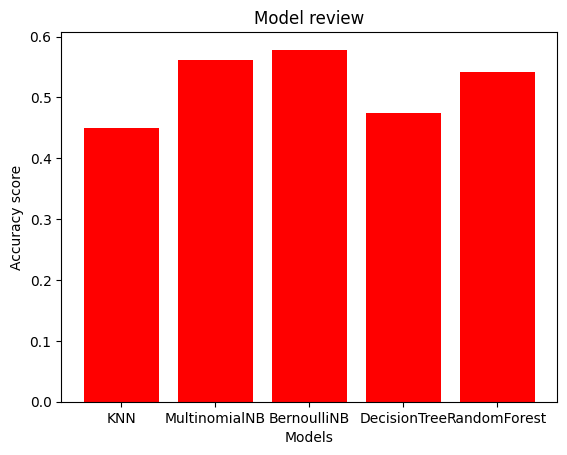

In [87]:
plt.bar(results['Models'],results['Accuracy'],color = 'r')
plt.title("Model review")
plt.xlabel("Models")
plt.ylabel("Accuracy score")

In [90]:
review =['the movie is very good']
data1 = vec.transform(review)
y_pred6=model3.predict(data1)
y_pred6
if y_pred6 == 1:
  print("Positive")
elif y_pred6 == -1:
  print("Negative")
else:
  print("Neutral")

Positive
